# Amber Index: Europe's wildfire protection gap

A 0–100 score per EU-27 country and year. **Higher = more fire danger relative to firefighting readiness.**
Bands: **Green** < 40 ≤ **Amber** < 60 ≤ **Red**.

| Pillar | Raises or lowers the score | Indicators |
|---|---|---|
| Danger | raises | burned area as % of land (GWIS via Our World in Data) |
| Hazards | raises | other hazards happening in the country (GDACS: floods, earthquakes, droughts, storms, volcanoes, wildfires): all alerts weighted Green 0.5, Orange 3, Red 9, and major (Orange/Red) alerts, each as a percentile among EU countries that year (this cancels GDACS's growing coverage) |
| Workforce | lowers | professional firefighters per 100k inhabitants (Eurostat LFS); volunteers if provided |
| Capability | lowers | fire-protection spending per inhabitant (Eurostat COFOG); fire stations per 1,000 km² and per 100k (OpenStreetMap) |

**Power** (0–100) estimates how much firefighting capacity a country can actually use: readiness (workforce and capability),
reduced by the hazard pressure it is under at the same time: `power = 100 · readiness · (1 − α · pressure)`, α = 0.5, pressure = ½ danger + ½ hazards.

All transformation logic lives in the `amber/` package, so the API applies exactly what this notebook trains.

## 1. Setup and configuration
Years, country list, cache behaviour and the random seed. `REFRESH = True` downloads every source again; scaling and imputation are fitted on 2014–2020 only (`TRAIN_LAST`).

In [1]:
import os, sys, json, warnings
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
os.chdir(ROOT); sys.path.insert(0, str(ROOT))
warnings.filterwarnings("ignore")

import numpy as np, pandas as pd, matplotlib.pyplot as plt
from amber import EU27, NAMES, SEED, SOURCES, data
from amber.features import build_panel, tidy_indicators, compute_rates, active_features, Preprocessor, FEATURES, PILLARS
from amber import scoring, pipeline, model as M
from amber.power import add_power, ALPHA

REFRESH = False
FIRST_YEAR, TRAIN_LAST = 2014, 2020
np.random.seed(SEED)
pd.set_option("display.width", 140, "display.max_columns", 20)

## 2. Fetch and cache every source
Each download is cached under `data/raw/` and reused unless `REFRESH=True`. OpenStreetMap counts come from the Overpass API with backoff and mirrors; countries that still fail stay missing.

In [2]:
src = pipeline.load_sources(REFRESH, FIRST_YEAR)
spending, population, area, burned = src["spending"], src["population"], src["area"], src["burned"]
firefighters, stations, hazard_events = src["firefighters"], src["stations"], src["hazard_events"]
YEARS = src["years"]; LAST_YEAR = YEARS[-1]
print(f"Years {FIRST_YEAR}-{LAST_YEAR}; firefighter files cover {sorted(firefighters.year.unique())}")

Years 2014-2025; firefighter files cover [np.int64(2022), np.int64(2023), np.int64(2024)]


In [3]:
for name, df in [("spending", spending), ("population", population), ("area", area), ("burned area", burned),
                 ("firefighters", firefighters), ("OSM stations", stations), ("GDACS hazard events", hazard_events)]:
    print(f"--- {name}: {df.shape}"); display(df.head(3))

--- spending: (732, 3)


,geo,year,spending_meur
0,AT,1995,310.2
1,AT,1996,311.7
2,AT,1997,330.0


--- population: (1740, 3)


,geo,year,population
0,AT,1960,7030385.0
1,AT,1961,7064693.0
2,AT,1962,7107904.0


--- area: (378, 3)


,geo,year,area_km2
0,AT,2013,83882.0
1,AT,2014,83882.0
2,AT,2015,83882.0


... (4 outputs left out)

--- OSM stations: (27, 3)


,iso2,stations,fetched
0,AT,4059.0,2026-11-14
1,BE,330.0,2026-11-14
2,BG,156.0,2026-11-14


--- GDACS hazard events: (2502, 7)


,iso2,eventid,eventtype,alertlevel,start,end,name
0,RO,1001443,WF,Green,2021-07-13 00:00:00,2021-07-28 00:00:00,Forest fires in Romania
1,DE,1101505,FL,Green,2022-06-30 01:00:00,2022-07-01 01:00:00,Flood in Germany
2,DE,1101468,FL,Green,2022-06-05 01:00:00,2022-06-07 01:00:00,"Flood in Germany, Switzerland"


## 3. One tidy indicator table and one wide table
`indicators(iso2, year, indicator, value, source, imputed)` plus a wide country-year panel. Firefighter counts exist only for 2022–2024, so other years copy the nearest year and are flagged `imputed`; the OSM station snapshot is applied to every year.

In [4]:
panel = pipeline.build(src)
indicators = tidy_indicators(panel)
display(indicators.sample(5, random_state=SEED))

,iso2,year,indicator,value,source,imputed
2313,HR,2023,hazard_load,2.5,GDACS alerts,False
2089,HU,2015,volunteers,NaN,manual,True
761,FR,2019,area_km2,638475.0,Eurostat reg_area3,False
829,LV,2015,area_km2,64594.0,Eurostat reg_area3,False
1961,BE,2019,volunteers,NaN,manual,True


In [5]:
missing = (indicators.groupby(["iso2", "indicator"])["imputed"].mean().unstack().mul(100).round(0))
missing = missing.drop(columns=["volunteers"]) if panel.volunteers.isna().all() else missing
print("Share of years not directly observed (%), before model imputation")
display(missing.style.background_gradient(cmap="Greys", vmin=0, vmax=100).format("{:.0f}"))

Share of years not directly observed (%), before model imputation


indicator,area_km2,burned_ha,firefighters,hazard_load,population,spending_meur,stations
iso2,,,,,,,
AT,0,0,100,0,0,8,0
BE,0,0,75,0,0,8,0
BG,0,0,75,0,0,8,0
CY,0,0,75,0,0,8,0
CZ,0,0,75,0,0,8,0
DE,0,0,75,0,0,8,0
DK,0,0,92,0,0,8,0
EE,0,0,83,0,0,8,0
ES,0,0,75,0,0,8,0


## 4. Feature engineering
Per-capita and per-area rates → `log1p` (all are right-skewed) → winsorise at the 5th/95th percentile → min-max to 0–1. **The percentiles are fitted on 2014–2020 only** and stored in the preprocessor.

In [6]:
rates = compute_rates(panel)
FEATS = active_features(panel)
meta = panel[["iso2", "year"]]
train_rows = panel.year <= TRAIN_LAST
pre = Preprocessor(FEATS).fit(rates.loc[train_rows, FEATS])
print("Features:", FEATS)
display(pd.DataFrame({"winsor_lo (log1p)": pre.lo, "winsor_hi (log1p)": pre.hi}).round(3))

Features: ['burned_share_pct', 'hazard_alerts', 'major_hazards', 'ff_per_100k', 'spend_per_capita', 'stations_per_1000km2', 'stations_per_100k']


,winsor_lo (log1p),winsor_hi (log1p)
burned_share_pct,0.000,0.450
hazard_alerts,0.000,0.962
major_hazards,0.000,0.000
ff_per_100k,3.720,5.430
spend_per_capita,3.102,4.675
stations_per_1000km2,0.847,4.414
stations_per_100k,1.116,3.883


## 5. Imputation
An `IterativeImputer`, fitted on the training years, fills what is still missing after scaling. The `imputed` mask records every value that was not observed.

In [7]:
rates, X, imputed_mask = pipeline.transform(panel, pre, FEATS)
print("Imputed share by feature (%):"); display(imputed_mask.mean().mul(100).round(1).to_frame("imputed %"))

Imputed share by feature (%):


,imputed %
burned_share_pct,0.0
hazard_alerts,0.0
major_hazards,0.0
ff_per_100k,80.6
spend_per_capita,8.0
stations_per_1000km2,22.2
stations_per_100k,22.2


## 6. Baseline index: equal weights
Equal weights inside each pillar and across the three pillars. Score = 100 · sigmoid(k · (Danger − Readiness − c)), with c the training median and k chosen so the 5th–95th percentile maps to about 5–95.

In [8]:
W_EQ = scoring.equal_weights(FEATS)
scale_eq = scoring.fit_scale(scoring.gap(scoring.pillar_scores(X[train_rows], W_EQ), W_EQ))
base = scoring.score_table(X, meta, W_EQ, scale_eq)
base[base.year == LAST_YEAR].sort_values("amber", ascending=False).head(10).round(2)

,iso2,year,danger,hazards,workforce,capability,readiness,amber,band,rank
311,ES,2025,1.00,0.50,0.40,0.24,0.32,96.54,Red,1
263,PT,2025,1.00,0.44,0.59,0.24,0.42,93.86,Red,2
35,BG,2025,0.53,0.34,0.57,0.16,0.37,83.70,Red,3
59,CY,2025,1.00,0.10,0.71,0.31,0.51,81.77,Red,4
179,IT,2025,0.34,0.46,0.35,0.37,0.36,81.69,Red,5
143,GR,2025,0.71,0.50,0.82,0.33,0.58,80.80,Red,6
275,RO,2025,0.48,0.38,0.64,0.32,0.48,74.61,Red,7
83,DK,2025,0.00,0.14,0.00,0.29,0.15,72.56,Red,8
299,SI,2025,0.02,0.26,0.19,0.44,0.31,62.50,Red,9
227,MT,2025,0.00,0.00,0.00,0.40,0.20,59.18,Amber,10


In [9]:
print("Bands, latest year:", base[base.year == LAST_YEAR]["band"].value_counts().to_dict())

Bands, latest year: {'Amber': 10, 'Red': 9, 'Green': 8}


## 7. Machine learning: what predicts next year's burned area?
Target: burned area (% of land) in year *t+1*. Features: readiness indicators and current danger at year *t*. ElasticNet baseline vs LightGBM (depth 3, 300 trees, monotone: more readiness can only lower the prediction, more danger can only raise it). A naive *persistence* forecast (next year = this year) is included as a reference. Rows are never shuffled.

In [10]:
table = M.ml_table(rates[FEATS], meta)
cv = M.evaluate(table, FEATS, split_year=TRAIN_LAST)
cv.round(3)

,model,validation,MAE,Spearman
0,ElasticNet,Leave one country out,0.127,0.648
1,ElasticNet,"Time split (train t<=2020, test t>=2021)",0.135,0.678
2,LightGBM,Leave one country out,0.133,0.567
3,LightGBM,"Time split (train t<=2020, test t>=2021)",0.119,0.516
4,Persistence,Leave one country out,0.136,0.718
5,Persistence,"Time split (train t<=2020, test t>=2021)",0.134,0.734


In [11]:
pick = cv.pivot(index="model", columns="validation", values="MAE")
best = pick.idxmin()
print("Lowest MAE per validation scheme:", best.to_dict())

Lowest MAE per validation scheme: {'Leave one country out': 'ElasticNet', 'Time split (train t<=2020, test t>=2021)': 'LightGBM'}


### Final model and SHAP weights
The deployed LightGBM is trained on every year with a known target, using the preprocessor fitted on 2014–2020. Mean |SHAP| per feature gives weights within each pillar; each pillar's share of total |SHAP| gives the pillar weight. Final weights blend 50% ML and 50% equal.

In [12]:
Xt = pre.transform(table[FEATS])
lgbm = M.make_lgbm(FEATS).fit(Xt, np.log1p(table["target_next"]))
W_ML, shap_values = M.shap_weights(lgbm, Xt)
W_FINAL = scoring.normalise(M.blend(W_ML, W_EQ, 0.5), FEATS)
weights_view = pd.DataFrame({"pillar": {f: FEATURES[f][0] for f in FEATS}, "w_ml": W_ML["within"],
                             "w_equal": W_EQ["within"], "w_final": W_FINAL["within"]})
pillar_view = pd.DataFrame({"w_ml": W_ML["pillar"], "w_equal": W_EQ["pillar"], "w_final": W_FINAL["pillar"]})
display(weights_view.round(3)); display(pillar_view.round(3))

,pillar,w_ml,w_equal,w_final
burned_share_pct,danger,1.000,1.000,1.000
hazard_alerts,hazards,1.000,0.500,0.750
major_hazards,hazards,0.000,0.500,0.250
ff_per_100k,workforce,1.000,1.000,1.000
spend_per_capita,capability,0.389,0.333,0.361
stations_per_1000km2,capability,0.493,0.333,0.413
stations_per_100k,capability,0.118,0.333,0.226


,w_ml,w_equal,w_final
danger,0.454,0.25,0.352
hazards,0.204,0.25,0.227
workforce,0.071,0.25,0.160
capability,0.272,0.25,0.261


## 8. Final scores and rank uncertainty
Scores with the blended weights. Monte Carlo: 500 runs with every weight perturbed by ±20%; `rank_lo`/`rank_hi` are the 5th/95th percentile ranks within each year.

In [13]:
scale = scoring.fit_scale(scoring.gap(scoring.pillar_scores(X[train_rows], W_FINAL), W_FINAL))
scores, ARCHETYPES = pipeline.score_all(panel, X, W_FINAL, scale, ALPHA)
print(f"k = {scale['k']:.2f}, c = {scale['c']:.3f}")
scores[scores.year == LAST_YEAR].sort_values("amber", ascending=False).head(10).round(2)

k = 6.56, c = -0.105


,iso2,year,danger,hazards,workforce,capability,readiness,amber,band,rank,rank_lo,rank_hi,hazard_pressure,power,power_rank,archetype
311,ES,2025,1.00,0.75,0.40,0.26,0.31,96.26,Red,1,1,1,0.88,17.59,27,Wildfire frontline
263,PT,2025,1.00,0.66,0.59,0.24,0.38,94.97,Red,2,2,2,0.83,22.02,25,Wildfire frontline
143,GR,2025,0.71,0.75,0.82,0.36,0.54,87.60,Red,3,3,4,0.73,34.17,16,Wildfire frontline
59,CY,2025,1.00,0.15,0.71,0.33,0.47,87.13,Red,4,3,5,0.57,33.67,17,Wildfire frontline
35,BG,2025,0.53,0.51,0.57,0.17,0.32,85.56,Red,5,4,5,0.52,23.83,24,Wildfire frontline
179,IT,2025,0.34,0.69,0.35,0.41,0.39,80.66,Red,6,6,7,0.51,28.74,23,Multi-hazard exposure
275,RO,2025,0.48,0.57,0.64,0.32,0.44,80.57,Red,7,6,7,0.53,32.60,18,Wildfire frontline
83,DK,2025,0.00,0.21,0.00,0.30,0.19,62.00,Red,8,8,9,0.11,17.80,26,Thin coverage
119,FR,2025,0.07,0.72,0.36,0.64,0.53,60.86,Red,9,8,10,0.39,42.66,11,Multi-hazard exposure
299,SI,2025,0.02,0.39,0.19,0.46,0.36,58.23,Amber,10,9,12,0.21,32.07,19,Multi-hazard exposure


## 8b. Power: capacity left after concurrent hazards
Readiness (workforce and capability) reduced by the hazard pressure each country is under that year. A country with strong services but many simultaneous hazards has less power to spare.

In [14]:
latest = scores[scores.year == LAST_YEAR].sort_values("power", ascending=False)
latest.assign(country=latest.iso2.map(NAMES))[["power_rank", "country", "power", "readiness", "hazard_pressure", "danger", "hazards"]].round(3).reset_index(drop=True)

,power_rank,country,power,readiness,hazard_pressure,danger,hazards
0,1,Czechia,76.507,0.876,0.252,0.055,0.45
1,2,Austria,67.700,0.751,0.198,0.006,0.39
2,3,Germany,63.563,0.750,0.306,0.041,0.57
3,4,Estonia,61.617,0.616,0.001,0.002,0.00
4,5,Croatia,56.418,0.654,0.275,0.039,0.51
5,6,Luxembourg,54.737,0.573,0.090,0.000,0.18
6,7,Latvia,48.333,0.483,0.000,0.000,0.00
7,8,Finland,43.382,0.434,0.000,0.000,0.00
8,9,Poland,42.974,0.513,0.325,0.020,0.63
9,10,Belgium,42.932,0.465,0.152,0.005,0.30


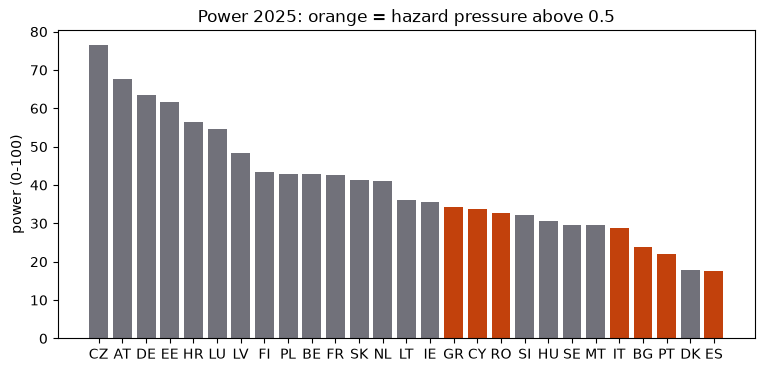

In [15]:
fig, ax = plt.subplots(figsize=(9, 4))
ax.bar(latest.iso2, latest.power, color=["#c2410c" if p > 0.5 else "#71717a" for p in latest.hazard_pressure])
ax.set_ylabel("power (0-100)"); ax.set_title(f"Power {LAST_YEAR}: orange = hazard pressure above 0.5"); plt.show()

## 9. Clustering
KMeans with 3 clusters on the pillar scores checks whether the band cut-offs separate real groups; KMeans with 4 clusters (fitted in `pipeline.score_all`) gives archetypes with plain-language names. The centres are saved, so later refreshes place new years into the same archetypes.

In [16]:
from sklearn.cluster import KMeans
P = scores[[p for p in PILLARS if p in scores]]
k3 = KMeans(3, n_init=10, random_state=SEED).fit(P)
check = scores.assign(cluster=k3.labels_).groupby("cluster").agg(mean_amber=("amber", "mean"), n=("amber", "size"))
display(check.sort_values("mean_amber").round(1))
display(pd.crosstab(scores.assign(cluster=k3.labels_)["cluster"], scores["band"]))

,mean_amber,n
cluster,,
1,42.7,133
0,50.4,121
2,87.9,70


band,Amber,Green,Red
cluster,,,
0,65,30,26
1,54,62,17
2,0,0,70


In [17]:
display(pd.DataFrame(ARCHETYPES["centers"], columns=ARCHETYPES["pillars"]).assign(archetype=ARCHETYPES["labels"]).round(2))
scores[scores.year == LAST_YEAR].groupby("archetype")["iso2"].apply(lambda s: ", ".join(sorted(s)))

,danger,hazards,workforce,capability,archetype
0,0.05,0.13,0.76,0.27,Well-resourced
1,0.07,0.54,0.41,0.49,Multi-hazard exposure
2,0.72,0.61,0.62,0.19,Wildfire frontline
3,0.01,0.07,0.29,0.54,Thin coverage


archetype
Multi-hazard exposure    AT, CZ, DE, FR, IE, IT, PL, SI
Thin coverage            BE, DK, FI, LT, LU, MT, NL, SE
Well-resourced                       EE, HR, HU, LV, SK
Wildfire frontline               BG, CY, ES, GR, PT, RO
Name: iso2, dtype: str

## 10. Visuals
Map of the latest year, the leaderboard, and which features drive the model.

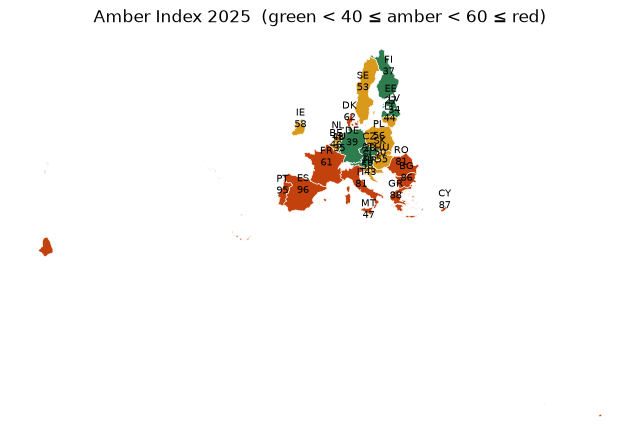

In [18]:
gdf = data.load_boundaries(REFRESH).merge(scores[scores.year == LAST_YEAR], on="iso2")
from matplotlib.colors import ListedColormap, BoundaryNorm
cmap, norm = ListedColormap(["#2f7d4f", "#d99a1c", "#c2410c"]), BoundaryNorm([0, 40, 60, 100], 3)
ax = gdf.to_crs(3035).plot(column="amber", cmap=cmap, norm=norm, edgecolor="white", linewidth=0.4, figsize=(8, 7), legend=False)
for _, r in gdf.to_crs(3035).iterrows():
    ax.annotate(f"{r.iso2}\n{r.amber:.0f}", r.geometry.representative_point().coords[0], ha="center", fontsize=7)
ax.set_title(f"Amber Index {LAST_YEAR}  (green < 40 ≤ amber < 60 ≤ red)"); ax.set_axis_off(); plt.show()

In [19]:
board = scores[scores.year == LAST_YEAR].sort_values("amber", ascending=False)
board.assign(country=board.iso2.map(NAMES), rank_range=board.rank_lo.astype(str) + "–" + board.rank_hi.astype(str))[
    ["rank", "country", "amber", "band", "rank_range", "danger", "hazards", "workforce", "capability", "power", "archetype"]].round(2).reset_index(drop=True)

,rank,country,amber,band,rank_range,danger,hazards,workforce,capability,power,archetype
0,1,Spain,96.26,Red,1–1,1.00,0.75,0.40,0.26,17.59,Wildfire frontline
1,2,Portugal,94.97,Red,2–2,1.00,0.66,0.59,0.24,22.02,Wildfire frontline
2,3,Greece,87.60,Red,3–4,0.71,0.75,0.82,0.36,34.17,Wildfire frontline
3,4,Cyprus,87.13,Red,3–5,1.00,0.15,0.71,0.33,33.67,Wildfire frontline
4,5,Bulgaria,85.56,Red,4–5,0.53,0.51,0.57,0.17,23.83,Wildfire frontline
5,6,Italy,80.66,Red,6–7,0.34,0.69,0.35,0.41,28.74,Multi-hazard exposure
6,7,Romania,80.57,Red,6–7,0.48,0.57,0.64,0.32,32.60,Wildfire frontline
7,8,Denmark,62.00,Red,8–9,0.00,0.21,0.00,0.30,17.80,Thin coverage
8,9,France,60.86,Red,8–10,0.07,0.72,0.36,0.64,42.66,Multi-hazard exposure
9,10,Slovenia,58.23,Amber,9–12,0.02,0.39,0.19,0.46,32.07,Multi-hazard exposure


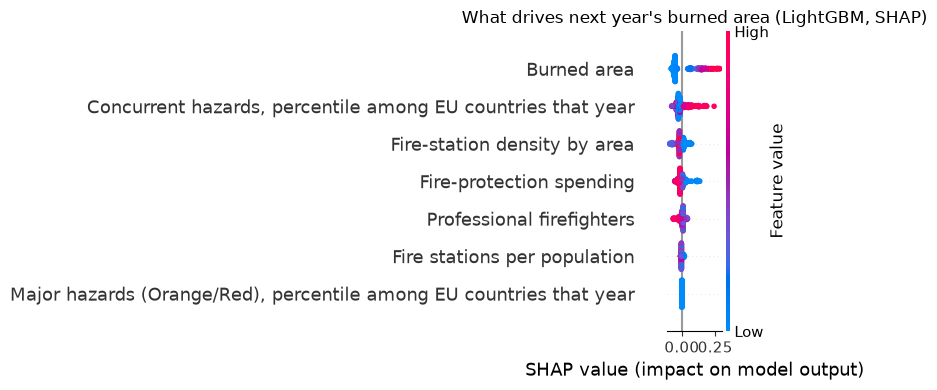

In [20]:
import shap
shap.summary_plot(shap_values.to_numpy(), Xt, feature_names=[FEATURES[f][3] for f in FEATS], show=False, plot_size=(8, 4))
plt.title("What drives next year's burned area (LightGBM, SHAP)"); plt.tight_layout(); plt.show()

## 11. Simulations: forcing hazards on strong and weak countries
We force hazard events on chosen countries in the latest year. Two things happen: the annual hazard indicators rise (recomputed through the same preprocessor), and the emergency **ties up crews**: each event demands firefighters by severity (Green 50, Orange 500, Red 2,000; an assumption), and power falls by the share of the national workforce that demand consumes. A *multi-hazard* shock is one Red flood, one Red wildfire and one Orange earthquake (4,500 firefighters).

In [21]:
from amber.simulate import PRESETS, run_scenario
raw_latest = rates[panel.year == LAST_YEAR].assign(iso2=panel.iso2, area_km2=panel.area_km2, hazard_load=panel.hazard_load,
    major_load=panel.major_load, firefighters_est=panel.firefighters_est).set_index("iso2")
strong, weak = latest.iso2.head(3).tolist(), latest.iso2.tail(3).tolist()
scenarios = {
    "Multi-hazard hits the 3 strongest": {i: PRESETS["multi_hazard"] for i in strong},
    "Multi-hazard hits the 3 weakest": {i: PRESETS["multi_hazard"] for i in weak},
    f"Major flood in {strong[0]}, wildfire season in {weak[-1]}": {strong[0]: PRESETS["major_flood"], weak[-1]: PRESETS["wildfire_season"]},
}
sims = {name: run_scenario(raw_latest, shocks, pre, FEATS, W_FINAL, scale, ALPHA, LAST_YEAR) for name, shocks in scenarios.items()}
print("Strongest:", strong, "| weakest:", weak)

Strongest: ['CZ', 'AT', 'DE'] | weakest: ['PT', 'DK', 'ES']


In [22]:
summary = pd.concat({name: df[df.shocked][["firefighters", "crew_demand", "committed_share", "power_before", "power_after", "power_rank_before", "power_rank_after", "rank_change", "unmet_demand"]]
                     for name, df in sims.items()}, names=["scenario", "iso2"])
summary.round(1)

firefighters  crew_demand  committed_share  power_before  power_after  power_rank_before  \
scenario                                 iso2                                                                                             
Multi-hazard hits the 3 strongest        DE         65723.0       4500.0              0.1          63.6         56.6                  3   
                                         CZ         17467.0       4500.0              0.3          76.5         52.9                  1   
                                         AT          8154.0       4500.0              0.6          67.7         28.3                  2   
Multi-hazard hits the 3 weakest          ES         39388.0       4500.0              0.1          17.6         15.6                 27   
                                         PT         12820.0       4500.0              0.4          22.0         13.7                 25   
                                         DK          2338.0       4500.0              1.0          17.8          0.8                 26   
Major flood in CZ, wildfire season in ES CZ         17467.0       2000.0              0.1          76.5         63.7                  1   
                                         ES         39388.0       1500.0              0.0          17.6         16.9                 27   

                                               power_rank_after  rank_change  unmet_demand  
scenario                                 iso2                                               
Multi-hazard hits the 3 strongest        DE                   3            0           0.0  
                                         CZ                   5            4           0.0  
                                         AT                  23           21           0.0  
Multi-hazard hits the 3 weakest          ES                  25           -2           0.0  
                                         PT                  26            1           0.0  
                                         DK                  27            1        2278.9  
Major flood in CZ, wildfire season in ES CZ                   3            2           0.0  
                                         ES                  27            0           0.0

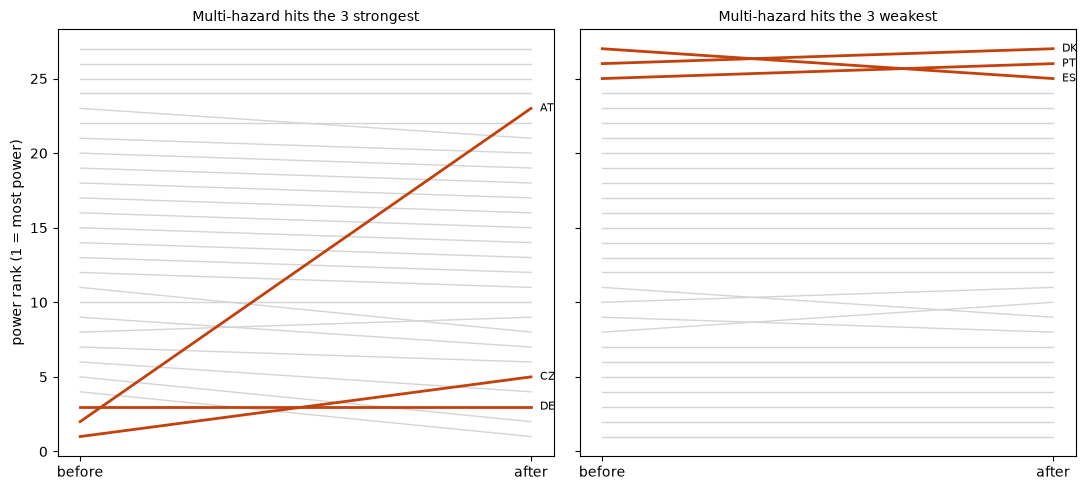

In [23]:
fig, axes = plt.subplots(1, 2, figsize=(11, 5), sharey=True)
for ax, name in zip(axes, list(sims)[:2]):
    df = sims[name]
    for iso2, r in df.iterrows():
        ax.plot([0, 1], [r.power_rank_before, r.power_rank_after], color="#c2410c" if r.shocked else "#d4d4d8", lw=2 if r.shocked else 1)
        if r.shocked:
            ax.annotate(iso2, (1.02, r.power_rank_after), va="center", fontsize=8)
    ax.set_xticks([0, 1], ["before", "after"]); ax.set_title(name, fontsize=10); ax.invert_yaxis()
axes[0].set_ylabel("power rank (1 = most power)"); plt.tight_layout(); plt.show()

In [24]:
pd.DataFrame({name: {"mean rank drop of shocked countries": df[df.shocked].rank_change.mean(),
                     "mean power lost": -df[df.shocked].power_change.mean()} for name, df in sims.items()}).T.round(1)

,mean rank drop of shocked countries,mean power lost
Multi-hazard hits the 3 strongest,8.3,23.3
Multi-hazard hits the 3 weakest,0.0,9.1
"Major flood in CZ, wildfire season in ES",1.0,6.8


## 12. Assistance optimizer: who sends how many firefighters
When a country needs crews it cannot cover itself, a linear program splits the request across the other countries. Each donor can send at most 5% of its workforce, reduced by its own hazard pressure and by crews tied up in its own emergencies; donors below power 20 send none; no donor covers more than 40% of the request. The cost of each firefighter balances **location** (distance from the donor's centroid to the incident) against **power** (prefer donors with capacity to spare): `cost = w · distance / max distance + (1 − w) · (1 − power / 100)`, w = 0.5.

In [25]:
from amber.optimize import AssistanceParams, donor_table, optimize_assistance
centroids = data.country_centroids(data.load_boundaries(REFRESH))
weak_case = sims["Multi-hazard hits the 3 weakest"]
recipient = weak_case.unmet_demand.idxmax()
need = float(weak_case.loc[recipient, "unmet_demand"])
plan, info = optimize_assistance(donor_table(weak_case, centroids), recipient, need)
print(f"{NAMES[recipient]} needs {need:,.0f} firefighters it cannot cover:", {k: info[k] for k in ["covered", "shortfall", "donors", "mean_distance_km"]})
plan.assign(country=plan.index.map(NAMES)).round(3)

Denmark needs 2,279 firefighters it cannot cover: {'covered': 2278, 'shortfall': 0.900000000000091, 'donors': 6, 'mean_distance_km': 736.7725415548158}


,sent,share_of_need,share_of_own_crews,distance_km,power,power_after,capacity,cost,country
iso2,,,,,,,,,
DE,911.0,0.400,0.014,577.117,64.125,63.237,2331.113,0.277,Germany
CZ,665.0,0.292,0.038,825.748,77.163,74.226,665.941,0.253,Czechia
AT,333.0,0.146,0.041,1021.598,68.210,65.425,333.155,0.331,Austria
NL,210.0,0.092,0.029,522.280,41.423,40.234,316.184,0.381,Netherlands
EE,134.0,0.059,0.050,1006.830,61.617,58.559,134.858,0.362,Estonia
LU,25.0,0.011,0.045,748.227,54.737,52.255,25.089,0.353,Luxembourg


In [26]:
base_case = run_scenario(raw_latest, {"PT": PRESETS["wildfire_season"] + [("WF", "Red", 1)]}, pre, FEATS, W_FINAL, scale, ALPHA, LAST_YEAR)
table_pt = donor_table(base_case, centroids)
trade_off = {}
for w in (0.0, 0.5, 1.0):
    p, i = optimize_assistance(table_pt, "PT", 3000, params=AssistanceParams(weight_location=w))
    trade_off[f"w={w}"] = p["sent"]
print("Portugal asks for 3,000 firefighters: w=0 prefers power, w=1 prefers proximity")
pd.DataFrame(trade_off).fillna(0).astype(int).sort_values("w=0.5", ascending=False)

Portugal asks for 3,000 firefighters: w=0 prefers power, w=1 prefers proximity


,w=0.0,w=0.5,w=1.0
iso2,,,
FR,61,1200,1200
DE,1200,796,0
CZ,652,652,0
AT,327,327,0
LU,25,25,25
BE,0,0,346
EE,134,0,0
FI,187,0,0
HR,277,0,0


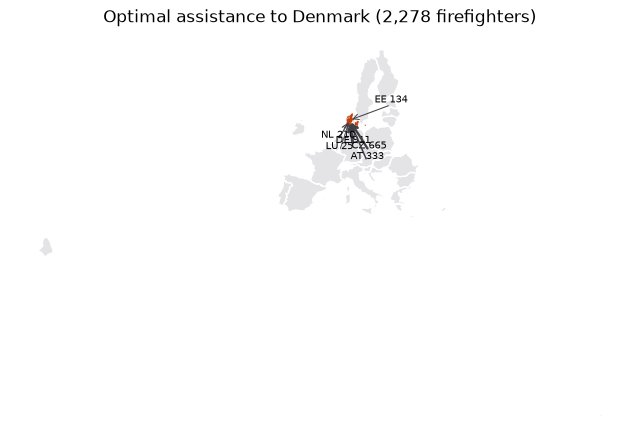

In [27]:
gdf_map = data.load_boundaries(REFRESH).to_crs(3035)
ax = gdf_map.plot(color="#e4e4e7", edgecolor="white", figsize=(8, 7))
gdf_map[gdf_map.iso2 == recipient].plot(ax=ax, color="#c2410c")
import geopandas as gpd
pts = gpd.GeoDataFrame(centroids, geometry=gpd.points_from_xy(centroids.lon, centroids.lat), crs=4326).to_crs(3035)
dst = pts.loc[recipient].geometry
for iso2, r in plan.iterrows():
    src = pts.loc[iso2].geometry
    ax.annotate("", xy=(dst.x, dst.y), xytext=(src.x, src.y), arrowprops=dict(arrowstyle="->", color="#3f3f46", lw=0.5 + 4 * r.share_of_need))
    ax.annotate(f"{iso2} {int(r.sent)}", (src.x, src.y), fontsize=7, ha="center", va="bottom")
ax.set_title(f"Optimal assistance to {NAMES[recipient]} ({info['covered']:,} firefighters)"); ax.set_axis_off(); plt.show()

## 13. Save artifacts and prove the round-trip
Everything the API needs, written by `amber.model.save_artifacts`, then reloaded.

In [28]:
ref = Xt.mean()
records = pipeline.records(panel, rates, X, scores, imputed_mask, FEATS)
weights_json = {f: {"pillar": FEATURES[f][0], "w_ml": W_ML["within"][f], "w_equal": W_EQ["within"][f], "w_final": W_FINAL["within"][f]} for f in FEATS}
weights_json["_pillars"] = {p: {"w_ml": W_ML["pillar"][p], "w_equal": W_EQ["pillar"][p], "w_final": W_FINAL["pillar"][p]} for p in PILLARS}
metadata = {"feature_order": FEATS, "training_years": [FIRST_YEAR, TRAIN_LAST], "model_years": [int(table.year.min()), int(table.year.max())],
            "latest_year": LAST_YEAR, "alpha": ALPHA, "archetypes": ARCHETYPES,
            "centroids": {i: [float(r.lat), float(r.lon)] for i, r in centroids.iterrows()}, "cv_metrics": cv.round(4).to_dict(orient="records"), "scale": scale,
            "reference": {f: float(v) for f, v in ref.items()}, "bands": {"green_below": 40, "red_from": 60},
            "target": "burned area as % of land area in year t+1 (model predicts log1p)", "sources": SOURCES}
paths = M.save_artifacts(lgbm, pre, weights_json, records, metadata)
[p.name for p in paths]

['model.joblib',
 'preprocessor.joblib',
 'weights.json',
 'scores.json',
 'metadata.json']

In [29]:
art = M.load_artifacts()
again = art["model"].predict(art["preprocessor"].transform(table[FEATS].head(5)))
assert np.allclose(again, lgbm.predict(Xt.head(5))), "round-trip mismatch"
print("Round-trip OK:", len(art["scores"]), "score rows,", art["metadata"]["feature_order"])

Round-trip OK: 324 score rows, ['burned_share_pct', 'hazard_alerts', 'major_hazards', 'ff_per_100k', 'spend_per_capita', 'stations_per_1000km2', 'stations_per_100k']
